Reference: (3000, 2006, 3)
Defective: (3000, 2052, 3)


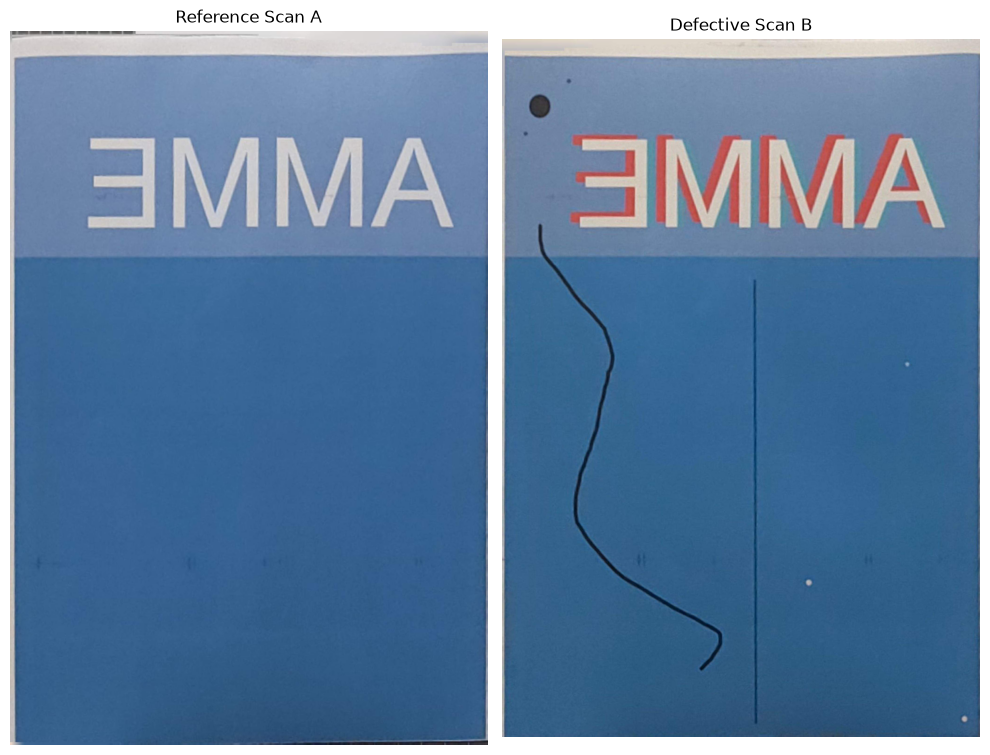

In [2]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

root = Path(r"D:\AMME5710_Major_Project")
folder = root / "real_scan"

output_dir = root / "results" / "real_scan"
output_dir.mkdir(parents=True, exist_ok=True)

A = cv2.imread(str(folder / "reference_scan.jpg"))
B = cv2.imread(str(folder / "defective_scan.jpg"))

if A is None or B is None:
    raise FileNotFoundError("Cannot read the scan images.")

print("Reference:", A.shape)
print("Defective:", B.shape)

fig, axes = plt.subplots(1, 2, figsize=(10, 8))

for ax, img, title in zip(
    axes,
    [A, B],
    ["Reference Scan A", "Defective Scan B"]
):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [3]:
# Reference image size
H, W = A.shape[:2]

# Initially resize B to match A
B_resized = cv2.resize(B, (W, H))

# Downsample images for faster registration
scale = 0.35

def prepare_for_ecc(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    small = cv2.resize(
        gray,
        (int(W * scale), int(H * scale))
    )

    return cv2.GaussianBlur(small, (5, 5), 0)

A_small = prepare_for_ecc(A)
B_small = prepare_for_ecc(B_resized)

# Initial affine transform
warp_matrix = np.eye(2, 3, dtype=np.float32)

criteria = (
    cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT,
    300,
    1e-6
)

# Estimate geometric alignment
cc, warp_matrix = cv2.findTransformECC(
    A_small,
    B_small,
    warp_matrix,
    cv2.MOTION_AFFINE,
    criteria,
    None,
    5
)

# Convert translation to original image scale
warp_matrix[:, 2] /= scale

# Align B with A
B_aligned = cv2.warpAffine(
    B_resized,
    warp_matrix,
    (W, H),
    flags=cv2.INTER_LINEAR | cv2.WARP_INVERSE_MAP,
    borderMode=cv2.BORDER_CONSTANT,
    borderValue=(255, 255, 255)
)

print("ECC correlation:", cc)
print("Warp matrix:")
print(warp_matrix)

cv2.imwrite(
    str(output_dir / "defective_aligned.png"),
    B_aligned
)


ECC correlation: 0.9754080520614601
Warp matrix:
[[ 1.0033115e+00 -4.2438903e-03 -2.6407161e+00]
 [ 2.1390831e-03  1.0170227e+00 -2.9070129e+01]]


True

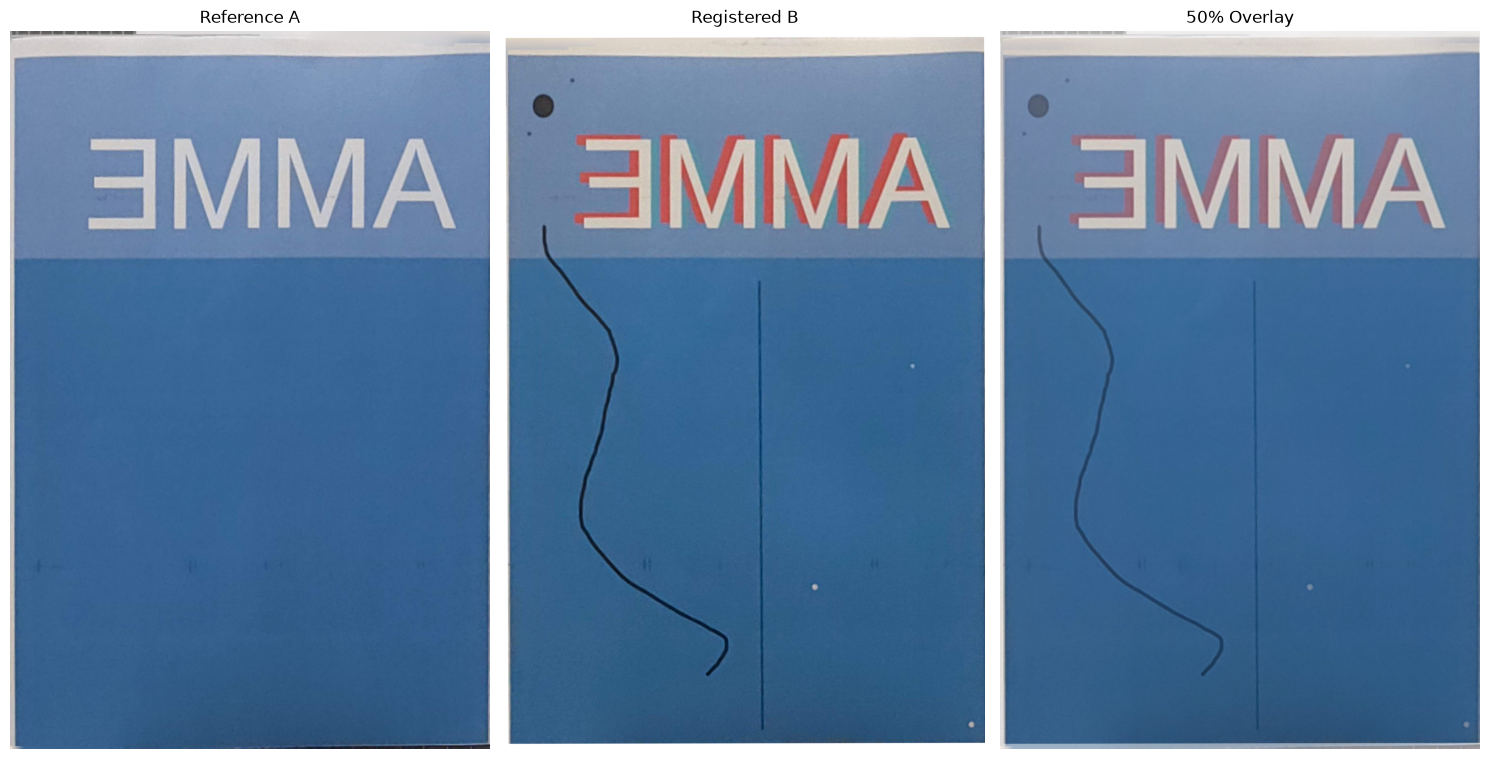

True

In [4]:
# Blend the two images at 50% opacity
overlay = cv2.addWeighted(
    A, 0.5,
    B_aligned, 0.5,
    0
)

fig, axes = plt.subplots(1, 3, figsize=(15, 8))

images = [A, B_aligned, overlay]
titles = [
    "Reference A",
    "Registered B",
    "50% Overlay"
]

for ax, img, title in zip(axes, images, titles):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

cv2.imwrite(
    str(output_dir / "registration_overlay.png"),
    overlay
)


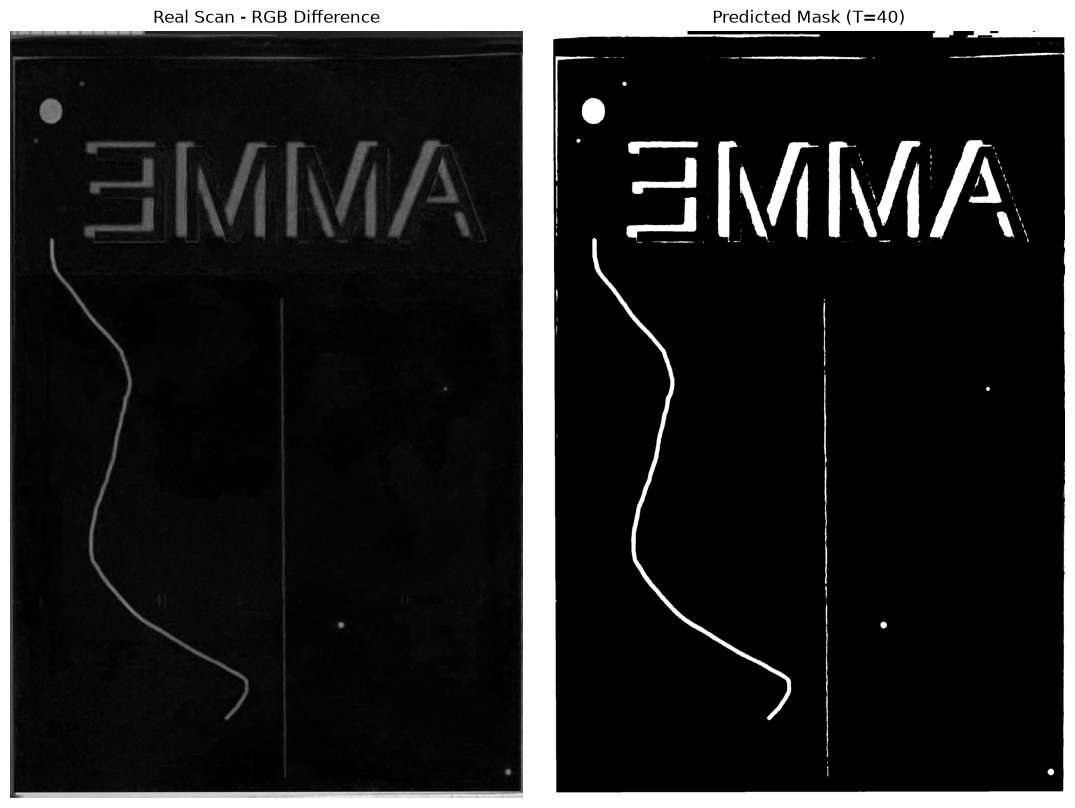

Detected pixels: 354136


True

In [5]:
# RGB maximum-channel difference
colour_diff = cv2.absdiff(A, B_aligned)
diff_rgb = np.max(colour_diff, axis=2)

# Initial threshold
T = 40
pred_mask = (diff_rgb > T).astype(np.uint8) * 255

fig, axes = plt.subplots(1, 2, figsize=(11, 8))

axes[0].imshow(diff_rgb, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Real Scan - RGB Difference")

axes[1].imshow(pred_mask, cmap="gray", vmin=0, vmax=255)
axes[1].set_title(f"Predicted Mask (T={T})")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Detected pixels:", np.count_nonzero(pred_mask))

cv2.imwrite(
    str(output_dir / "rgb_difference.png"),
    diff_rgb
)

cv2.imwrite(
    str(output_dir / "predicted_mask.png"),
    pred_mask
)


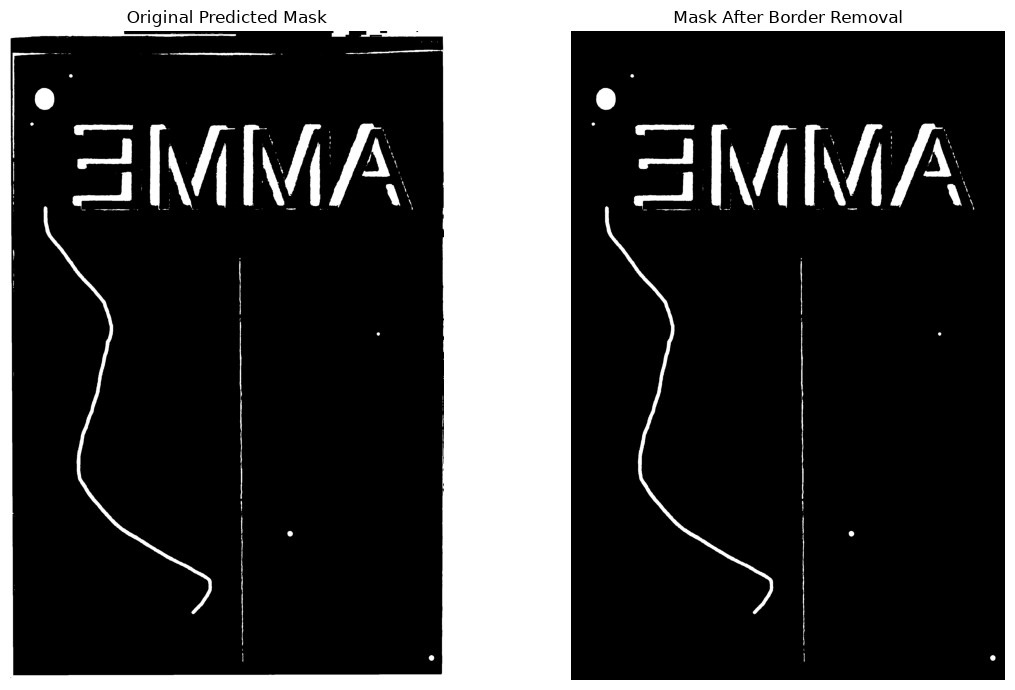

In [6]:
# Image dimensions
H, W = diff_rgb.shape

# Valid inspection region
valid_mask = np.zeros((H, W), dtype=np.uint8)

# Exclude outer borders
left = int(W * 0.015)
right = int(W * 0.985)

top = int(H * 0.04)
bottom = int(H * 0.99)

valid_mask[top:bottom, left:right] = 255

# Apply inspection region to predicted mask
clean_mask = cv2.bitwise_and(
    pred_mask,
    valid_mask
)

# Display comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 7))

axes[0].imshow(pred_mask, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original Predicted Mask")

axes[1].imshow(clean_mask, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Mask After Border Removal")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


Total components: 140
Remaining candidates: 71


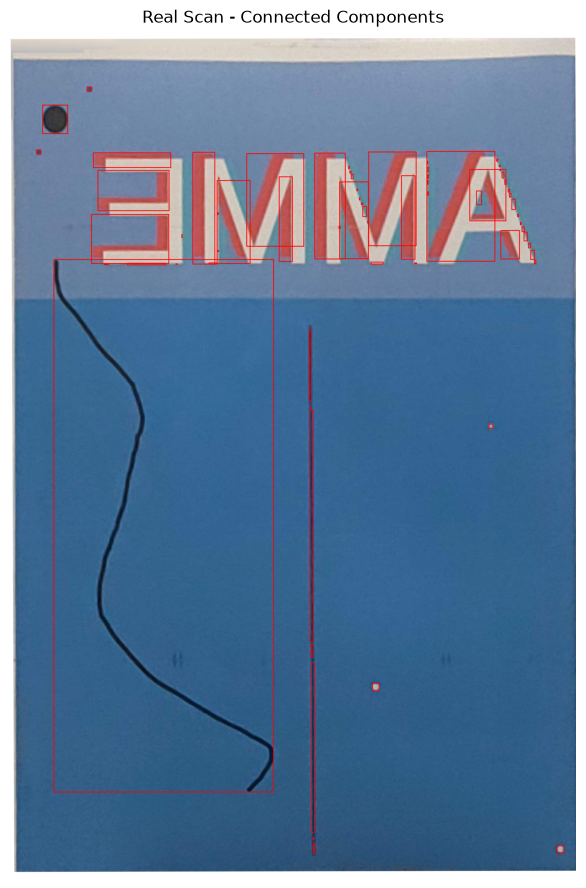

In [7]:
num_labels, labels, stats, centroids = (
    cv2.connectedComponentsWithStats(
        clean_mask,
        connectivity=8
    )
)

min_area = 10
candidates = []

for label_id in range(1, num_labels):

    x, y, w, h, area = stats[label_id]

    if area < min_area:
        continue

    candidates.append({
        "id": label_id,
        "x": int(x),
        "y": int(y),
        "w": int(w),
        "h": int(h),
        "area": int(area)
    })

candidates = sorted(
    candidates,
    key=lambda c: c["area"],
    reverse=True
)

print("Total components:", num_labels - 1)
print("Remaining candidates:", len(candidates))

# Draw bounding boxes
result = B_aligned.copy()

for c in candidates:
    x, y, w, h = c["x"], c["y"], c["w"], c["h"]

    cv2.rectangle(
        result,
        (x, y),
        (x + w - 1, y + h - 1),
        (0, 0, 255),
        2
    )

plt.figure(figsize=(8, 11))
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Real Scan - Connected Components")
plt.axis("off")
plt.show()


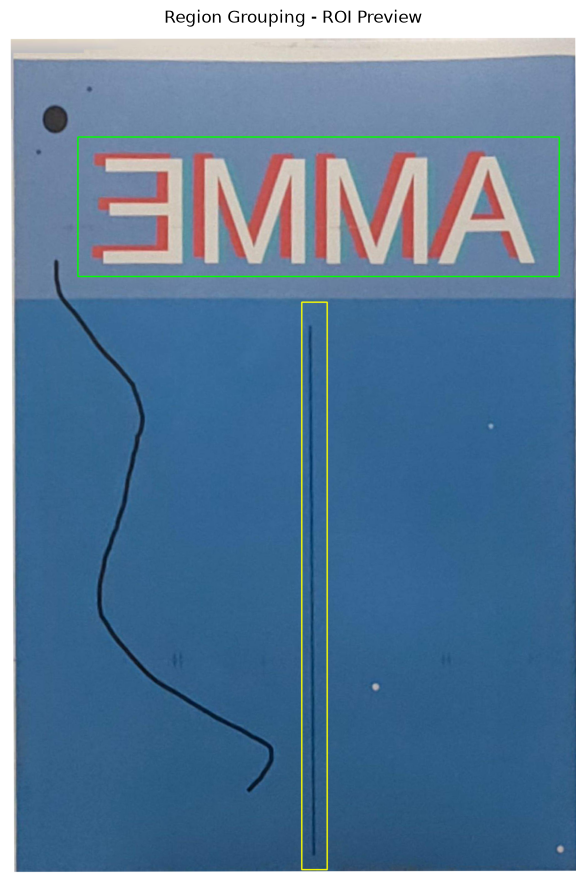

In [13]:
H, W = clean_mask.shape

# AMME Color Shift region
text_roi = (
    int(W * 0.12),
    int(H * 0.125),
    int(W * 0.97),
    int(H * 0.29)
)

# Vertical Line region
line_roi = (
    int(W * 0.515),
    int(H * 0.32),
    int(W * 0.56),
    int(H * 0.99)
)

# Preview selected regions
preview = B_aligned.copy()

# Green: Color Shift
cv2.rectangle(
    preview,
    (text_roi[0], text_roi[1]),
    (text_roi[2], text_roi[3]),
    (0, 255, 0),
    3
)

# Yellow: Line
cv2.rectangle(
    preview,
    (line_roi[0], line_roi[1]),
    (line_roi[2], line_roi[3]),
    (0, 255, 255),
    3
)

plt.figure(figsize=(8, 11))
plt.imshow(cv2.cvtColor(preview, cv2.COLOR_BGR2RGB))
plt.title("Region Grouping - ROI Preview")
plt.axis("off")
plt.show()


In [14]:
# Create a mask for a selected ROI
def extract_roi_mask(mask, roi):
    x1, y1, x2, y2 = roi

    output = np.zeros_like(mask)
    output[y1:y2, x1:x2] = mask[y1:y2, x1:x2]

    return output


# Group Color Shift and Line
text_mask = extract_roi_mask(clean_mask, text_roi)
line_mask = extract_roi_mask(clean_mask, line_roi)

# Remove these regions from the remaining mask
remaining_mask = clean_mask.copy()

for roi in [text_roi, line_roi]:
    x1, y1, x2, y2 = roi
    remaining_mask[y1:y2, x1:x2] = 0

# Find other independent components
num_other, other_labels, other_stats, _ = (
    cv2.connectedComponentsWithStats(
        remaining_mask,
        connectivity=8
    )
)

region_masks = []

# Add grouped regions
region_masks.append({
    "name": "AMME Group",
    "mask": text_mask
})

region_masks.append({
    "name": "Line Group",
    "mask": line_mask
})

# Keep all other significant components
min_area = 30

for label_id in range(1, num_other):

    area = other_stats[label_id, cv2.CC_STAT_AREA]

    if area < min_area:
        continue

    component_mask = (
        (other_labels == label_id).astype(np.uint8) * 255
    )

    region_masks.append({
        "name": f"Region {label_id}",
        "mask": component_mask
    })

print("Total regions:", len(region_masks))
print("AMME pixels:", np.count_nonzero(text_mask))
print("Line pixels:", np.count_nonzero(line_mask))


Total regions: 9
AMME pixels: 171900
Line pixels: 8434


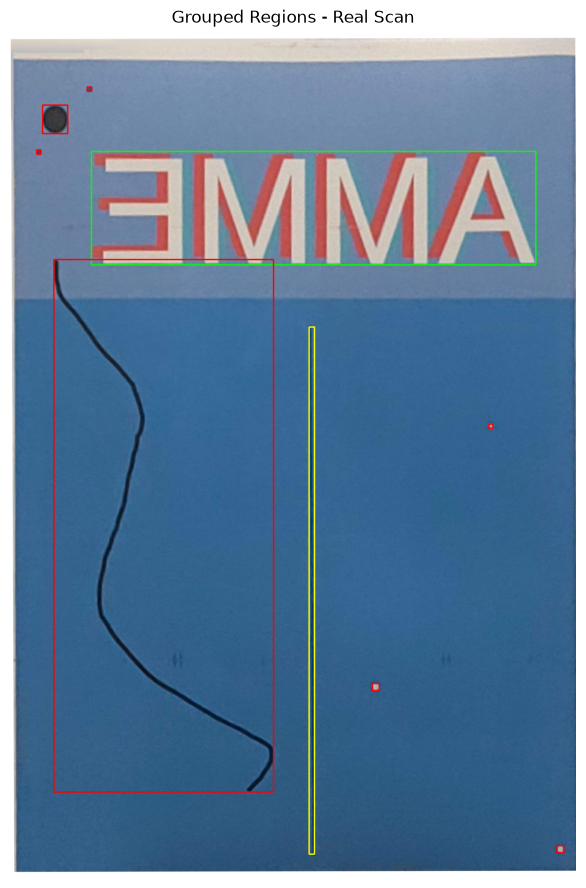

In [15]:
result = B_aligned.copy()

colors = [
    (0, 255, 0),    # Green: AMME
    (0, 255, 255)   # Yellow: Line
]

for i, region in enumerate(region_masks):

    mask = region["mask"]

    points = cv2.findNonZero(mask)

    if points is None:
        continue

    x, y, w, h = cv2.boundingRect(points)

    color = colors[i] if i < 2 else (0, 0, 255)

    cv2.rectangle(
        result,
        (x, y),
        (x + w - 1, y + h - 1),
        color,
        3
    )

plt.figure(figsize=(8, 11))
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Grouped Regions - Real Scan")
plt.axis("off")
plt.show()


In [17]:
import joblib
from skimage.feature import hog

# Load trained SVM
model_path = root / "svm_classes.joblib"

model = joblib.load(model_path)

print("SVM loaded successfully!")
print("Classes:", model.classes_)


SVM loaded successfully!
Classes: ['blackspot' 'colorshift' 'hair' 'line' 'pinhole']


In [18]:
def extract_features(A, B, mask):

    region = mask > 0

    if not np.any(region):
        return None

    ys, xs = np.where(region)

    x_min, x_max = xs.min(), xs.max()
    y_min, y_max = ys.min(), ys.max()

    width = x_max - x_min + 1
    height = y_max - y_min + 1

    # Crop region with padding
    pad = 8

    x1 = max(0, x_min - pad)
    x2 = min(B.shape[1], x_max + pad + 1)
    y1 = max(0, y_min - pad)
    y2 = min(B.shape[0], y_max + pad + 1)

    diff = cv2.absdiff(A, B)
    diff_crop = diff[y1:y2, x1:x2]

    # HOG features
    diff_gray = cv2.cvtColor(
        diff_crop, cv2.COLOR_BGR2GRAY
    )

    diff_resized = cv2.resize(
        diff_gray, (32, 32),
        interpolation=cv2.INTER_AREA
    )

    hog_features = hog(
        diff_resized,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys",
        feature_vector=True
    )

    # Colour features
    defect_pixels = diff[region].astype(np.float32)

    colour_features = np.concatenate([
        defect_pixels.mean(axis=0) / 255.0,
        defect_pixels.std(axis=0) / 255.0
    ])

    # Shape features
    area = np.count_nonzero(region)

    shape_features = np.array([
        area / region.size,
        width / B.shape[1],
        height / B.shape[0],
        width / max(height, 1)
    ], dtype=np.float32)

    return np.concatenate([
        hog_features,
        colour_features,
        shape_features
    ])


In [19]:
predictions = []

for region in region_masks:

    mask = region["mask"]

    features = extract_features(
        A, B_aligned, mask
    )

    if features is None:
        continue

    # Predict category
    predicted_class = model.predict(
        features.reshape(1, -1)
    )[0]

    # Bounding box
    points = cv2.findNonZero(mask)
    x, y, w, h = cv2.boundingRect(points)

    predictions.append({
        "region": region["name"],
        "category": predicted_class,
        "x": x,
        "y": y,
        "w": w,
        "h": h
    })

    print(
        f"{region['name']}: "
        f"{predicted_class}, "
        f"position=({x},{y}), size={w}x{h}"
    )

print("\nTotal classified regions:", len(predictions))


AMME Group: colorshift, position=(288,426), size=1575x403
Line Group: colorshift, position=(1059,1048), size=20x1868
Region 1: blackspot, position=(273,198), size=17x16
Region 2: hair, position=(115,262), size=90x102
Region 3: blackspot, position=(94,421), size=16x16
Region 4: colorshift, position=(155,809), size=779x1887
Region 5: blackspot, position=(1696,1392), size=15x16
Region 6: blackspot, position=(1283,2310), size=26x27
Region 7: blackspot, position=(1937,2885), size=25x26

Total classified regions: 9


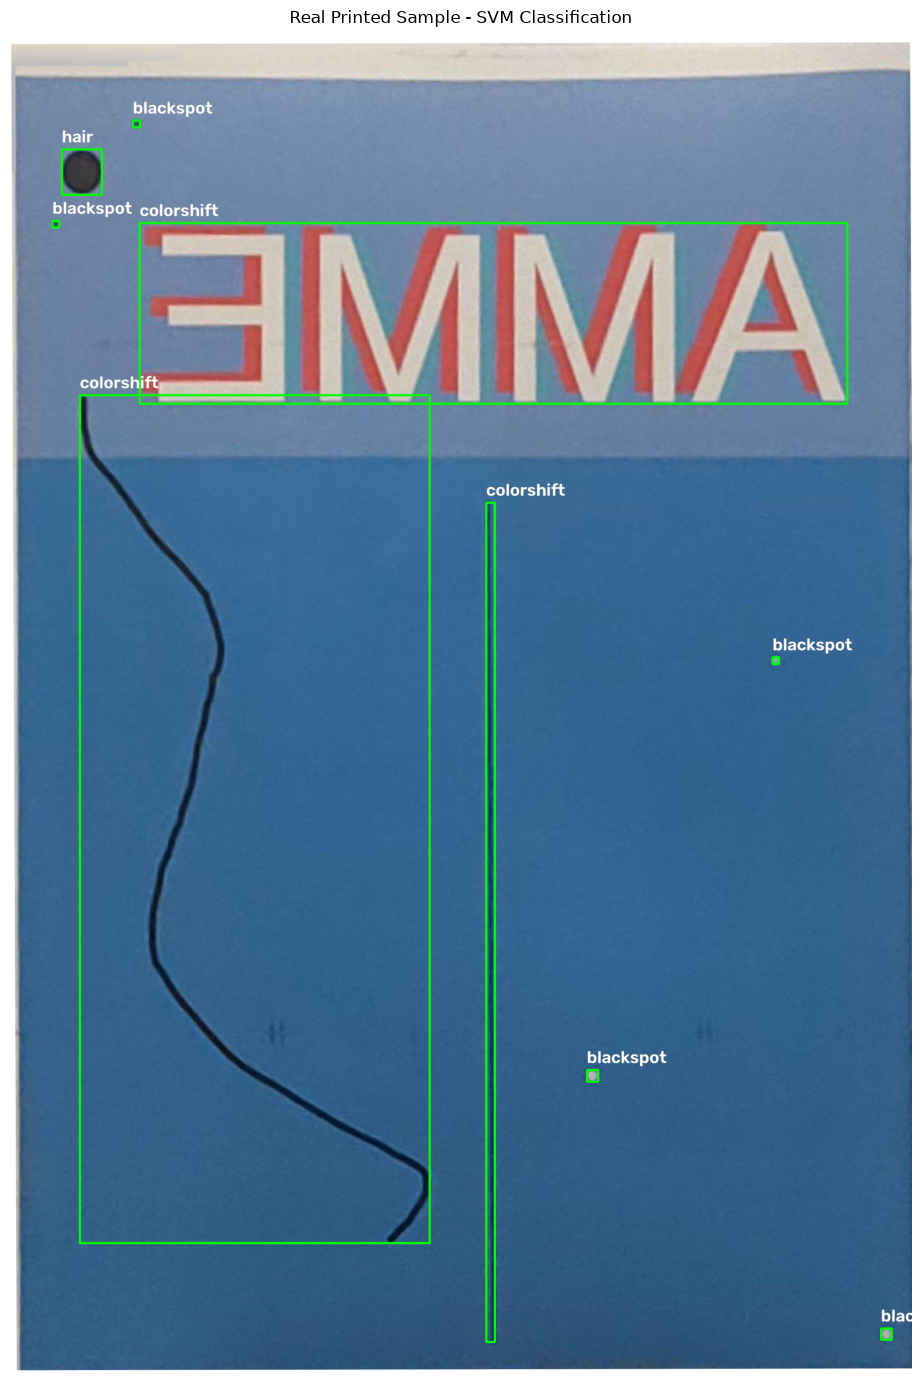

Saved to: D:\AMME5710_Major_Project\results\real_scan\real_scan_classified.png


In [20]:
annotated = B_aligned.copy()

for p in predictions:

    x, y = p["x"], p["y"]
    w, h = p["w"], p["h"]
    category = str(p["category"])

    # Bounding box
    cv2.rectangle(
        annotated,
        (x, y),
        (x + w - 1, y + h - 1),
        (0, 255, 0),
        3
    )

    # Text position
    text_x = x
    text_y = max(55, y - 15)

    # Black outline
    cv2.putText(
        annotated,
        category,
        (text_x, text_y),
        cv2.FONT_HERSHEY_SIMPLEX,
        1.3,
        (0, 0, 0),
        7
    )

    # White text
    cv2.putText(
        annotated,
        category,
        (text_x, text_y),
        cv2.FONT_HERSHEY_SIMPLEX,
        1.3,
        (255, 255, 255),
        3
    )

# Display
plt.figure(figsize=(10, 14))

plt.imshow(
    cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)
)

plt.title("Real Printed Sample - SVM Classification")
plt.axis("off")
plt.tight_layout()
plt.show()

# Save
output_path = output_dir / "real_scan_classified.png"

cv2.imwrite(str(output_path), annotated)

print("Saved to:", output_path)


In [21]:
import pandas as pd

rows = []

for region in region_masks:

    features = extract_features(
        A, B_aligned, region["mask"]
    )

    if features is None:
        continue

    X = features.reshape(1, -1)

    # SVM prediction
    prediction = model.predict(X)[0]

    # SVM decision scores
    scores = model.decision_function(X)[0]

    # Rank classes by score
    order = np.argsort(scores)[::-1]

    rows.append({
        "Region": region["name"],
        "Prediction": prediction,
        "Second-ranked": model.classes_[order[1]],
        "Area (pixels)": np.count_nonzero(region["mask"]),
        "Aspect ratio": round(float(features[333]), 2),
        "Mean B diff": round(float(features[324] * 255), 1),
        "Mean G diff": round(float(features[325] * 255), 1),
        "Mean R diff": round(float(features[326] * 255), 1),
        "Score gap": round(
            float(scores[order[0]] - scores[order[1]]), 3
        )
    })

analysis_df = pd.DataFrame(rows)

display(analysis_df)


,Region,Prediction,Second-ranked,Area (pixels),Aspect ratio,Mean B diff,Mean G diff,Mean R diff,Score gap
0,AMME Group,colorshift,pinhole,171900,3.91,75.1,42.8,63.2,2.321
1,Line Group,colorshift,hair,8434,0.01,44.5,38.8,45.4,0.988
2,Region 1,blackspot,hair,208,1.06,57.2,53.2,47.2,1.043
3,Region 2,hair,colorshift,7324,0.88,109.2,79.6,57.8,1.025
4,Region 3,blackspot,hair,184,1.00,56.3,51.3,47.3,1.071
5,Region 4,colorshift,hair,38712,0.41,85.2,60.5,38.2,1.060
6,Region 5,blackspot,hair,182,0.94,39.8,54.7,63.4,1.069
7,Region 6,blackspot,hair,518,0.96,31.7,63.6,96.8,1.044
8,Region 7,blackspot,hair,504,0.96,26.6,57.6,92.4,1.073


0: AMME Group, Position=(288, 426), Size=1575x403
1: Line Group, Position=(1059, 1048), Size=20x1868
2: Region 1, Position=(273, 198), Size=17x16
3: Region 2, Position=(115, 262), Size=90x102
4: Region 3, Position=(94, 421), Size=16x16
5: Region 4, Position=(155, 809), Size=779x1887
6: Region 5, Position=(1696, 1392), Size=15x16
7: Region 6, Position=(1283, 2310), Size=26x27
8: Region 7, Position=(1937, 2885), Size=25x26


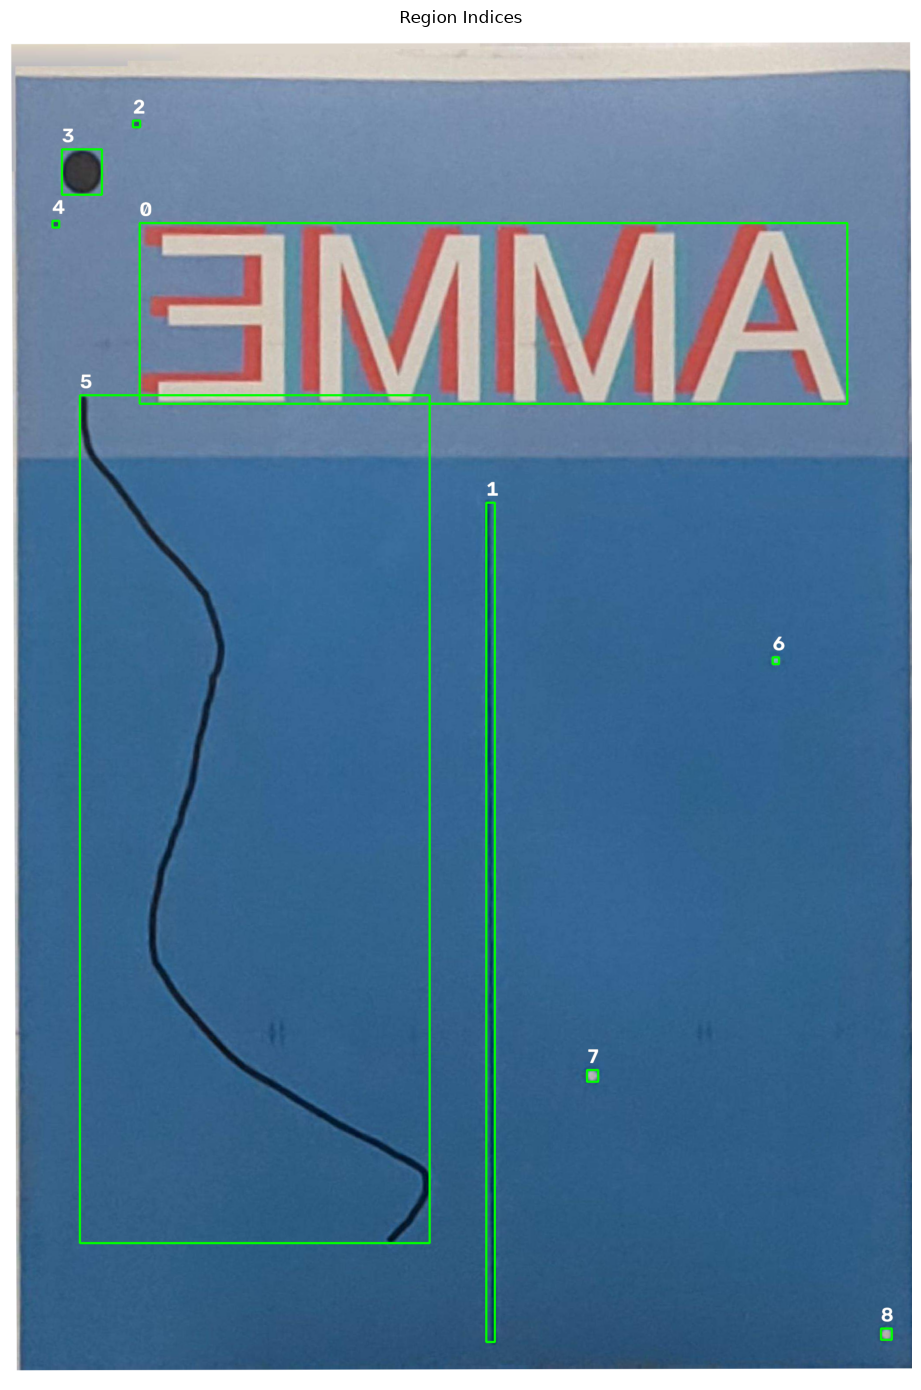

In [22]:
# Visualise region indices
indexed_image = B_aligned.copy()

for i, region in enumerate(region_masks):

    mask = region["mask"]

    points = cv2.findNonZero(mask)

    if points is None:
        continue

    x, y, w, h = cv2.boundingRect(points)

    # Draw bounding box
    cv2.rectangle(
        indexed_image,
        (x, y),
        (x + w - 1, y + h - 1),
        (0, 255, 0),
        3
    )

    # Draw region index
    cv2.putText(
        indexed_image,
        str(i),
        (x, max(45, y - 15)),
        cv2.FONT_HERSHEY_SIMPLEX,
        1.5,
        (0, 0, 0),
        7
    )

    cv2.putText(
        indexed_image,
        str(i),
        (x, max(45, y - 15)),
        cv2.FONT_HERSHEY_SIMPLEX,
        1.5,
        (255, 255, 255),
        3
    )

    print(
        f"{i}: {region['name']}, "
        f"Position=({x}, {y}), "
        f"Size={w}x{h}"
    )

plt.figure(figsize=(10, 14))

plt.imshow(
    cv2.cvtColor(indexed_image, cv2.COLOR_BGR2RGB)
)

plt.title("Region Indices")
plt.axis("off")
plt.tight_layout()
plt.show()
